## 1. Data: train and test
The test set is kept untouched until the final evaluation. All model selection uses cross-validation on the training set only.

## 0. Install the boosting libraries
XGBoost, LightGBM and CatBoost are advanced gradient-boosting libraries. Run this cell once (internet needed). Everything else in the notebook is unchanged, except that 3 boosting models are added to the 6 existing ones.

In [1]:
%pip install -q -U xgboost lightgbm catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42
N_ITER = 6          # random-search candidates per model (raise for a wider search)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [3]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

if os.path.exists('merged_train_test.csv'):
    df = pd.read_csv('merged_train_test.csv')
elif os.path.exists('merged.csv'):
    df = pd.read_csv('merged.csv')
else:
    df = pd.concat([pd.read_csv('train.csv'), pd.read_csv('test.csv')], ignore_index=True)

# Ab is single dataframe ko train aur test mein split karne ke liye yeh code likhein:
y = (df['Attrition'] == 'Left').astype(int)
X = df.drop(columns=['Employee ID', 'Attrition'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('train', X_train.shape, 'test', X_test.shape)
print('Left share: train %.3f, test %.3f' % (y_train.mean(), y_test.mean()))
print('Missing:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

train (59598, 22) test (14900, 22)
Left share: train 0.475, test 0.475
Missing: 0 0


In [4]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Merged file ko load karein (jo aapke folder mein mojood hai)
if os.path.exists('merged.csv'):
    df = pd.read_csv('merged.csv')
elif os.path.exists('merged_train_test.csv'):
    df = pd.read_csv('merged_train_test.csv')
else:
    # Agar koi merged file na mile toh purani files check karein
    df = pd.concat([pd.read_csv('train.csv'), pd.read_csv('test.csv')], ignore_index=True)

# 2. Target aur Features ko alag karein
y = (df['Attrition'] == 'Left').astype(int)
X = df.drop(columns=['Employee ID', 'Attrition'])

# 3. Train aur Test mein split karein (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('train', X_train.shape, 'test', X_test.shape)
print('Left share: train %.3f, test %.3f' % (y_train.mean(), y_test.mean()))
print('Missing:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

train (59598, 22) test (14900, 22)
Left share: train 0.475, test 0.475
Missing: 0 0


## 2. Preprocessing pipeline
One `ColumnTransformer` handles every column type. Everything is fitted inside the pipeline, so during cross-validation each fold learns its encoders and scaling only from its own training part (no leakage).

| Group | Columns | Treatment |
|---|---|---|
| Numeric | 7 columns | StandardScaler |
| Ordinal | 8 columns | OrdinalEncoder in natural order, then StandardScaler |
| Binary | Gender, Overtime, Remote Work, Leadership and Innovation Opportunities | 0/1 |
| Nominal | Job Role, Marital Status | One-hot |

In [5]:
num_cols = ['Age','Years at Company','Monthly Income','Number of Promotions','Distance from Home','Number of Dependents','Company Tenure']
ord_map = {'Work-Life Balance': ['Poor','Fair','Good','Excellent'], 'Job Satisfaction': ['Low','Medium','High','Very High'],
           'Performance Rating': ['Low','Below Average','Average','High'],
           'Education Level': ['High School','Associate Degree','Bachelor’s Degree','Master’s Degree','PhD'],
           'Job Level': ['Entry','Mid','Senior'], 'Company Size': ['Small','Medium','Large'],
           'Company Reputation': ['Poor','Fair','Good','Excellent'], 'Employee Recognition': ['Low','Medium','High','Very High']}
ord_cols = list(ord_map)
bin_cols = ['Gender','Overtime','Remote Work','Leadership Opportunities','Innovation Opportunities']
nom_cols = ['Job Role','Marital Status']
assert sorted(num_cols + ord_cols + bin_cols + nom_cols) == sorted(X_train.columns)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('ord', Pipeline([('enc', OrdinalEncoder(categories=list(ord_map.values()))), ('sc', StandardScaler())]), ord_cols),
    ('bin', OneHotEncoder(drop='if_binary'), bin_cols),
    ('nom', OneHotEncoder(handle_unknown='ignore'), nom_cols)])
preprocess.fit(X_train)
feature_names = list(preprocess.get_feature_names_out())
print(len(feature_names), 'features after preprocessing')

28 features after preprocessing


## 3. Baseline and cross-validation of 9 models
The baseline (always predict the most common class) sets the floor every real model has to beat. All models are then scored with 5-fold stratified cross-validation on the training set, with default settings.

In [6]:
def make(model): return Pipeline([('prep', preprocess), ('model', model)])
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED),
    'KNN': KNeighborsClassifier(),
    'Random Forest': RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEED),
    'Extra Trees': ExtraTreesClassifier(n_estimators=150, n_jobs=-1, random_state=SEED),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=300, eval_metric='logloss', tree_method='hist', n_jobs=-1, random_state=SEED),
    'LightGBM': LGBMClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, verbose=-1),
    'CatBoost': CatBoostClassifier(iterations=300, thread_count=-1, random_seed=SEED, verbose=0, allow_writing_files=False)}
scoring = ['accuracy', 'roc_auc', 'f1']
rows = []
for name, m in {'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'), **models}.items():
    t0 = time.time(); r = cross_validate(make(m), X_train, y_train, cv=CV, scoring=scoring)
    rows.append([name, r['test_accuracy'].mean(), r['test_accuracy'].std(), r['test_roc_auc'].mean(), r['test_f1'].mean(), time.time() - t0])
cv_default = pd.DataFrame(rows, columns=['model','CV accuracy','accuracy std','CV ROC-AUC','CV F1','seconds']).set_index('model')
display(cv_default.round(4))

,CV accuracy,accuracy std,CV ROC-AUC,CV F1,seconds
model,,,,,
Baseline (most frequent),0.5252,0.0000,0.5000,0.0000,2.8473
Logistic Regression,0.7414,0.0044,0.8289,0.7255,3.1937
Decision Tree,0.6659,0.0037,0.6652,0.6488,5.7253
KNN,0.6776,0.0019,0.7320,0.6658,28.5446
Random Forest,0.7475,0.0033,0.8361,0.7308,44.0581
Extra Trees,0.7409,0.0041,0.8290,0.7241,49.1217
Gradient Boosting,0.7570,0.0025,0.8486,0.7441,12.7592
XGBoost,0.7390,0.0025,0.8267,0.7249,17.9270
LightGBM,0.7557,0.0027,0.8466,0.7432,12.8625


## 4. Hyperparameter tuning
`RandomizedSearchCV` (3-fold, scored by ROC-AUC) on the training set for each of the 9 models. ROC-AUC is used because it does not depend on the decision threshold.

In [7]:
grids = {
    'Logistic Regression': {'model__C': np.logspace(-3, 2, 20), 'model__class_weight': [None, 'balanced']},
    'Decision Tree': {'model__max_depth': [3, 5, 7, 10, 15, None], 'model__min_samples_leaf': [1, 5, 20, 50, 100], 'model__criterion': ['gini', 'entropy']},
    'KNN': {'model__n_neighbors': [15, 25, 35, 51, 75], 'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]},
    'Random Forest': {'model__n_estimators': [100, 200], 'model__max_depth': [8, 12, 16, None], 'model__min_samples_leaf': [1, 5, 10, 20], 'model__max_features': ['sqrt', 0.5]},
    'Extra Trees': {'model__n_estimators': [100, 200], 'model__max_depth': [8, 12, 16, None], 'model__min_samples_leaf': [1, 5, 10, 20], 'model__max_features': ['sqrt', 0.5]},
    'Gradient Boosting': {'model__learning_rate': [0.02, 0.05, 0.1, 0.2], 'model__max_leaf_nodes': [8, 15, 31], 'model__max_iter': [100, 200, 300], 'model__min_samples_leaf': [20, 50, 100], 'model__l2_regularization': [0, 1, 10]},
    'XGBoost': {'model__n_estimators': [200, 300, 500], 'model__max_depth': [3, 4, 5, 6], 'model__learning_rate': [0.02, 0.05, 0.1],
                'model__subsample': [0.7, 0.85, 1.0], 'model__colsample_bytree': [0.7, 0.85, 1.0],
                'model__min_child_weight': [1, 5, 10], 'model__reg_lambda': [1, 5, 10]},
    'LightGBM': {'model__n_estimators': [200, 300, 500], 'model__num_leaves': [15, 31, 63], 'model__learning_rate': [0.02, 0.05, 0.1],
                 'model__subsample': [0.7, 0.85, 1.0], 'model__subsample_freq': [1], 'model__colsample_bytree': [0.7, 0.85, 1.0],
                 'model__min_child_samples': [20, 50, 100], 'model__reg_lambda': [0, 1, 10]},
    'CatBoost': {'model__iterations': [200, 400, 600], 'model__depth': [4, 6, 8], 'model__learning_rate': [0.03, 0.05, 0.1],
                 'model__l2_leaf_reg': [1, 3, 5, 10]}}
tuned, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    s = RandomizedSearchCV(make(model), grids[name], n_iter=N_ITER, cv=3, scoring='roc_auc', random_state=SEED, n_jobs=1)
    s.fit(X_train, y_train); tuned[name] = s
    rows.append([name, cv_default.loc[name, 'CV ROC-AUC'], s.best_score_, time.time() - t0, {k.replace('model__', ''): v for k, v in s.best_params_.items()}])
    print('%-20s tuned CV ROC-AUC %.4f (%.0fs)' % (name, s.best_score_, time.time() - t0))
tune_df = pd.DataFrame(rows, columns=['model','default CV ROC-AUC','tuned CV ROC-AUC','seconds','best params']).set_index('model')
display(tune_df)

Logistic Regression  tuned CV ROC-AUC 0.8288 (12s)
Decision Tree        tuned CV ROC-AUC 0.8215 (12s)
KNN                  tuned CV ROC-AUC 0.8177 (277s)
Random Forest        tuned CV ROC-AUC 0.8410 (108s)
Extra Trees          tuned CV ROC-AUC 0.8354 (116s)
Gradient Boosting    tuned CV ROC-AUC 0.8507 (58s)
XGBoost              tuned CV ROC-AUC 0.8503 (76s)
LightGBM             tuned CV ROC-AUC 0.8492 (65s)
CatBoost             tuned CV ROC-AUC 0.8523 (136s)


,default CV ROC-AUC,tuned CV ROC-AUC,seconds,best params
model,,,,
Logistic Regression,0.828905,0.828800,11.514667,"{'class_weight': 'balanced', 'C': 0.2335721469..."
Decision Tree,0.665158,0.821457,12.245397,"{'min_samples_leaf': 100, 'max_depth': 15, 'cr..."
KNN,0.731972,0.817739,277.094586,"{'weights': 'distance', 'p': 1, 'n_neighbors':..."
Random Forest,0.836099,0.841038,108.214926,"{'n_estimators': 100, 'min_samples_leaf': 10, ..."
Extra Trees,0.828961,0.835403,115.573297,"{'n_estimators': 100, 'min_samples_leaf': 10, ..."
Gradient Boosting,0.848628,0.850700,58.389127,"{'min_samples_leaf': 20, 'max_leaf_nodes': 8, ..."
XGBoost,0.826683,0.850341,75.669652,"{'subsample': 1.0, 'reg_lambda': 5, 'n_estimat..."
LightGBM,0.846640,0.849232,65.242096,"{'subsample_freq': 1, 'subsample': 0.7, 'reg_l..."
CatBoost,0.847355,0.852289,136.046018,"{'learning_rate': 0.05, 'l2_leaf_reg': 10, 'it..."


## 5. Final evaluation on the test set
Each tuned model (already refitted on the full training set) is scored once on the test set. The best model is chosen by tuned **cross-validation** score, not by test score, so the test set stays an honest estimate.

In [8]:
rows, preds, probs = [], {}, {}
for name, s in tuned.items():
    preds[name] = s.predict(X_test); probs[name] = s.predict_proba(X_test)[:, 1]
    rows.append([name, accuracy_score(y_test, preds[name]), precision_score(y_test, preds[name]), recall_score(y_test, preds[name]),
                 f1_score(y_test, preds[name]), roc_auc_score(y_test, probs[name]), accuracy_score(y_train, s.predict(X_train))])
base = DummyClassifier(strategy='most_frequent').fit(X_train, y_train); bp = base.predict(X_test)
rows.insert(0, ['Baseline (most frequent)', accuracy_score(y_test, bp), 0.0, 0.0, 0.0, 0.5, accuracy_score(y_train, base.predict(X_train))])
final = pd.DataFrame(rows, columns=['model','test accuracy','precision','recall','F1','ROC-AUC','train accuracy']).set_index('model')
final['CV ROC-AUC (tuned)'] = tune_df['tuned CV ROC-AUC']
display(final.round(4))
best = tune_df['tuned CV ROC-AUC'].idxmax(); print('Best model (by tuned CV ROC-AUC):', best)

,test accuracy,precision,recall,F1,ROC-AUC,train accuracy,CV ROC-AUC (tuned)
model,,,,,,,
Baseline (most frequent),0.5252,0.0000,0.0000,0.0000,0.5000,0.5252,NaN
Logistic Regression,0.7379,0.7160,0.7422,0.7289,0.8287,0.7426,0.8288
Decision Tree,0.7335,0.7134,0.7332,0.7232,0.8230,0.7565,0.8215
KNN,0.7374,0.7148,0.7436,0.7289,0.8225,1.0000,0.8177
Random Forest,0.7479,0.7383,0.7263,0.7323,0.8422,0.8160,0.8410
Extra Trees,0.7477,0.7317,0.7398,0.7357,0.8377,0.8241,0.8354
Gradient Boosting,0.7544,0.7384,0.7475,0.7430,0.8500,0.7652,0.8507
XGBoost,0.7536,0.7385,0.7448,0.7416,0.8492,0.7654,0.8503
LightGBM,0.7532,0.7383,0.7440,0.7411,0.8486,0.7790,0.8492


Best model (by tuned CV ROC-AUC): CatBoost


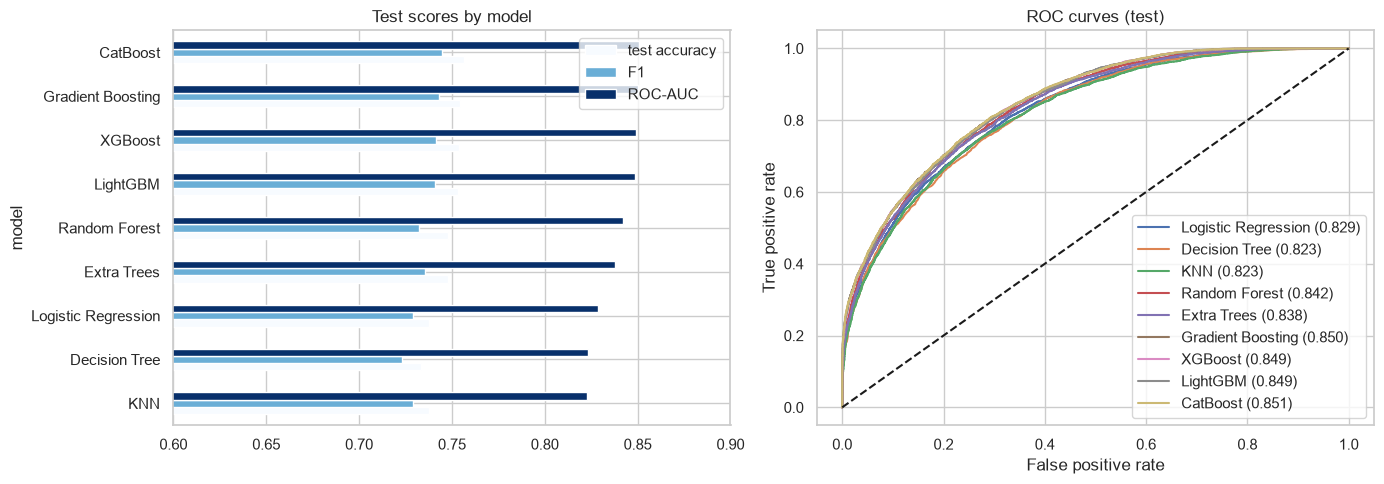

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
final.drop(index='Baseline (most frequent)')[['test accuracy','F1','ROC-AUC']].sort_values('ROC-AUC').plot.barh(ax=ax[0], colormap='Blues')
ax[0].set_xlim(0.6, 0.9); ax[0].set_title('Test scores by model')
for name in tuned:
    fpr, tpr, _ = roc_curve(y_test, probs[name]); ax[1].plot(fpr, tpr, label='%s (%.3f)' % (name, final.loc[name, 'ROC-AUC']))
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC curves (test)'); ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Best model in detail

              precision    recall  f1-score   support

      Stayed       0.77      0.76      0.77      7826
        Left       0.74      0.75      0.74      7074

    accuracy                           0.76     14900
   macro avg       0.76      0.76      0.76     14900
weighted avg       0.76      0.76      0.76     14900



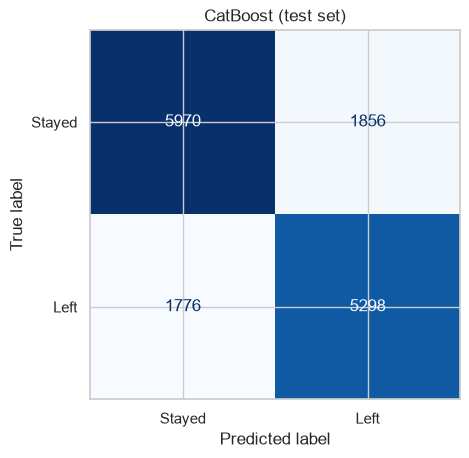

Best parameters: {'learning_rate': 0.05, 'l2_leaf_reg': 10, 'iterations': 200, 'depth': 4}


In [10]:
print(classification_report(y_test, preds[best], target_names=['Stayed', 'Left']))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds[best]), display_labels=['Stayed', 'Left']).plot(cmap='Blues', colorbar=False)
plt.title(best + ' (test set)'); plt.show()
print('Best parameters:', tune_df.loc[best, 'best params'])

### Feature importance (permutation, on test data)
Permutation importance measures how much the test ROC-AUC drops when one original column is shuffled. It works on the original columns, so one-hot columns are not split up.

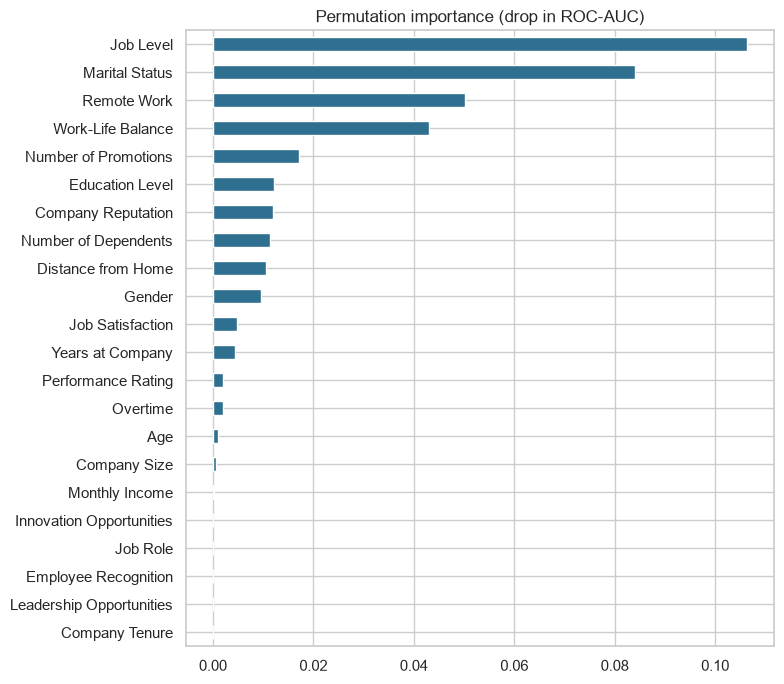

,importance
Job Level,0.1064
Marital Status,0.0840
Remote Work,0.0502
Work-Life Balance,0.0430
Number of Promotions,0.0171
Education Level,0.0122
Company Reputation,0.0119
Number of Dependents,0.0113
Distance from Home,0.0107
Gender,0.0096


In [11]:
pi = permutation_importance(tuned[best].best_estimator_, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(8, 7), color='#2f6f8f', title='Permutation importance (drop in ROC-AUC)'); plt.tight_layout(); plt.show()
display(imp.sort_values(ascending=False).head(10).round(4).to_frame('importance'))